# LAB02 — House Prices: Advanced Regression Techniques
## Dự đoán giá nhà bằng MLP trong PyTorch

**Môn:** Deep Learning  
**Bài toán:** Supervised Learning — Regression  
**Target:** `SalePrice`  
**Mô hình chính:** Multi-Layer Perceptron (MLP) bằng PyTorch  
**Metric chính:** RMSE trên `log1p(SalePrice)`  

Notebook được tổ chức theo tinh thần **CRISP-DM**:

1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Deployment

### Điểm kế thừa từ source mẫu
- Giữ luồng EDA → preprocessing → model → evaluation → submission.
- Giữ `log1p(SalePrice)`, MLP PyTorch, `MSELoss`, Adam, RMSE/MAE/R².
- Giữ 3 kiến trúc MLP để so sánh: `64-32-16`, `128-64-32`, `256-128-64`.

### Điểm cải tiến trong notebook này
- **Chia train/validation trước khi fit preprocessing** để tránh data leakage.
- Imputation, encoder và scaler **chỉ fit trên training fold**.
- Có **Ridge Regression** làm baseline.
- Có **Early Stopping** và lưu best model.
- Chạy nhiều seed trong cùng một notebook để đo **độ ổn định của MLP**.
- Refit preprocessing + final model trên **toàn bộ `train.csv`** trước khi dự đoán Kaggle test.
- Có bước kiểm tra prediction bất thường trước khi xuất `submission.csv`.

# 1. Import & Configuration

Tất cả tham số chính được gom vào `CONFIG` để dễ thay đổi kịch bản thí nghiệm.  
Ta tách hai loại seed:

- `split_seed`: cố định cách chia train/validation để các mô hình được so sánh trên **cùng một validation set**.
- `model_seeds`: thay đổi khởi tạo trọng số và thứ tự batch nhằm kiểm tra **độ ổn định của MLP**.

In [1]:
from pathlib import Path
import os
import random
import copy
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

torch.set_num_threads(min(4, os.cpu_count() or 1))
print("PyTorch CPU threads:", torch.get_num_threads())
print("Python working directory:", Path.cwd())
print("PyTorch version:", torch.__version__)

PyTorch CPU threads: 4
Python working directory: /Users/ducquang/Documents/DL-HOCSAU/house-prices-advanced-regression-techniques
PyTorch version: 2.14.0


In [2]:
CONFIG = {
    "data": {
        "validation_size": 0.20,
        "split_seed": 42,
    },
    "train": {
        "batch_size": 128,
        "learning_rate": 1e-3,
        "weight_decay": 1e-5,
        "max_epochs": 120,
        "patience": 12,
        "min_delta": 1e-5,
        "dropout": 0.10,
    },
    "experiments": {
        "architectures": [
            [64, 32, 16],
            [128, 64, 32],
            [256, 128, 64],
        ],
        "model_seeds": [42, 123, 2026],
    },
    "output_dir": "outputs",
}

OUTPUT_DIR = Path(CONFIG["output_dir"])
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)


def set_seed(seed: int = 42):
    """Cố định randomness để kết quả có thể tái lập."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Cấu hình deterministic khi có CUDA.
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(CONFIG["data"]["split_seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

Device: cpu
{
  "data": {
    "validation_size": 0.2,
    "split_seed": 42
  },
  "train": {
    "batch_size": 128,
    "learning_rate": 0.001,
    "weight_decay": 1e-05,
    "max_epochs": 120,
    "patience": 12,
    "min_delta": 1e-05,
    "dropout": 0.1
  },
  "experiments": {
    "architectures": [
      [
        64,
        32,
        16
      ],
      [
        128,
        64,
        32
      ],
      [
        256,
        128,
        64
      ]
    ],
    "model_seeds": [
      42,
      123,
      2026
    ]
  },
  "output_dir": "outputs"
}


# 2. Load Data

Notebook tự tìm dữ liệu ở một số vị trí phổ biến:

- Kaggle: `/kaggle/input/house-prices-advanced-regression-techniques/`
- Thư mục `data/`
- Thư mục hiện tại `./`

Các file cần có:

- `train.csv`
- `test.csv`
- `data_description.txt`
- `sample_submission.csv`

In [3]:
import zipfile

def find_data_dir():
    candidates = [
        Path("/kaggle/input/house-prices-advanced-regression-techniques"),
        Path("data"),
        Path("."),
    ]
    for d in candidates:
        if (d / "train.csv").exists() and (d / "test.csv").exists():
            return d

    # Nếu chỉ có file ZIP (thường gặp khi chạy Colab/local), tự giải nén vào data/.
    zip_candidates = [
        Path("house-prices-advanced-regression-techniques.zip"),
        Path("data/house-prices-advanced-regression-techniques.zip"),
    ]
    for zip_path in zip_candidates:
        if zip_path.exists():
            extract_dir = Path("data")
            extract_dir.mkdir(exist_ok=True)
            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(extract_dir)
            if (extract_dir / "train.csv").exists() and (extract_dir / "test.csv").exists():
                print(f"Đã tự giải nén dữ liệu từ {zip_path} -> {extract_dir}/")
                return extract_dir

    raise FileNotFoundError(
        "Không tìm thấy train.csv/test.csv hoặc file ZIP của competition. "
        "Hãy đặt dữ liệu vào thư mục data/ hoặc thư mục hiện tại."
    )

DATA_DIR = find_data_dir()
print("DATA_DIR =", DATA_DIR.resolve())

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)

display(train.head())

DATA_DIR = /Users/ducquang/Documents/DL-HOCSAU/house-prices-advanced-regression-techniques
Train shape: (1460, 81)
Test shape : (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0000,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.0000",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0000,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.0000",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0000,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.0000",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0000,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0000,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.0000",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0000,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0000,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.0000",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
desc_path = DATA_DIR / "data_description.txt"
if desc_path.exists():
    data_description = desc_path.read_text(encoding="utf-8", errors="ignore")
    print("Trích data_description.txt (1200 ký tự đầu):\n")
    print(data_description[:1200])
else:
    print("Không tìm thấy data_description.txt")

Trích data_description.txt (1200 ký tự đầu):

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
   

# 3. Business Understanding — CRISP-DM

## 3.1. Mục tiêu
Dự đoán **giá bán cuối cùng của một căn nhà (`SalePrice`)** dựa trên các đặc trưng mô tả căn nhà như:

- vị trí và khu dân cư;
- diện tích;
- chất lượng xây dựng;
- năm xây dựng/cải tạo;
- tầng hầm, garage, fireplace;
- số phòng và nhiều thuộc tính khác.

## 3.2. Loại bài toán
Đây là **bài toán hồi quy (Regression)** vì `SalePrice` là biến liên tục.

## 3.3. Mục tiêu Deep Learning
Xây dựng **MLP bằng PyTorch**, đánh giá khả năng tổng quát hóa trên validation set và so sánh các kiến trúc mạng.

## 3.4. Metric
Metric chính của notebook là:

$$
RMSE_{log} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(\log(1+y_i)-\hat{z}_i\right)^2}
$$

Trong đó `z = log1p(SalePrice)`.

Ngoài ra dùng thêm:

- **MAE ($)**: dễ diễn giải theo đơn vị giá nhà.
- **R²**: mức độ mô hình giải thích biến thiên của giá thực tế.

# 4. Data Understanding / EDA

Mục tiêu của EDA trong Lab này là **đủ để hiểu dữ liệu và hỗ trợ preprocessing**, không biến notebook thành một bài EDA quá dài.

In [5]:
print("Số dòng train:", len(train))
print("Số cột train:", train.shape[1])
print("Số dòng test :", len(test))
print("Số cột test :", test.shape[1])

print("\nKiểu dữ liệu trong train:")
display(train.dtypes.value_counts().rename("count").to_frame())

print("\nThống kê SalePrice:")
display(train["SalePrice"].describe().to_frame().T)

Số dòng train: 1460
Số cột train: 81
Số dòng test : 1459
Số cột test : 80

Kiểu dữ liệu trong train:


,count
str,43
int64,35
float64,3



Thống kê SalePrice:


,count,mean,std,min,25%,50%,75%,max
SalePrice,"1,460.0000","180,921.1959","79,442.5029","34,900.0000","129,975.0000","163,000.0000","214,000.0000","755,000.0000"


,missing_count,missing_pct
PoolQC,1453,99.5205
MiscFeature,1406,96.3014
Alley,1369,93.7671
Fence,1179,80.7534
MasVnrType,872,59.7260
FireplaceQu,690,47.2603
LotFrontage,259,17.7397
GarageType,81,5.5479
GarageYrBlt,81,5.5479
GarageFinish,81,5.5479


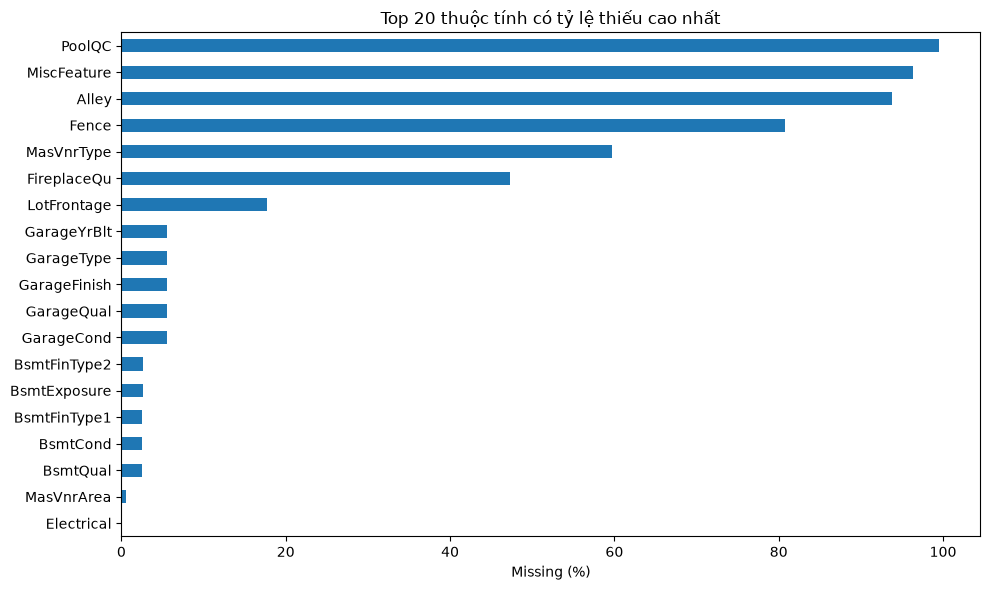

In [6]:
# Bảng missing values
missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_pct": train.isna().mean() * 100,
})
missing = missing[missing["missing_count"] > 0].sort_values("missing_pct", ascending=False)

display(missing.head(25))

plt.figure(figsize=(10, 6))
missing.head(20)["missing_pct"].sort_values().plot(kind="barh")
plt.title("Top 20 thuộc tính có tỷ lệ thiếu cao nhất")
plt.xlabel("Missing (%)")
plt.tight_layout()
plt.savefig(FIG_DIR / "missing_top20.png", dpi=150, bbox_inches="tight")
plt.show()

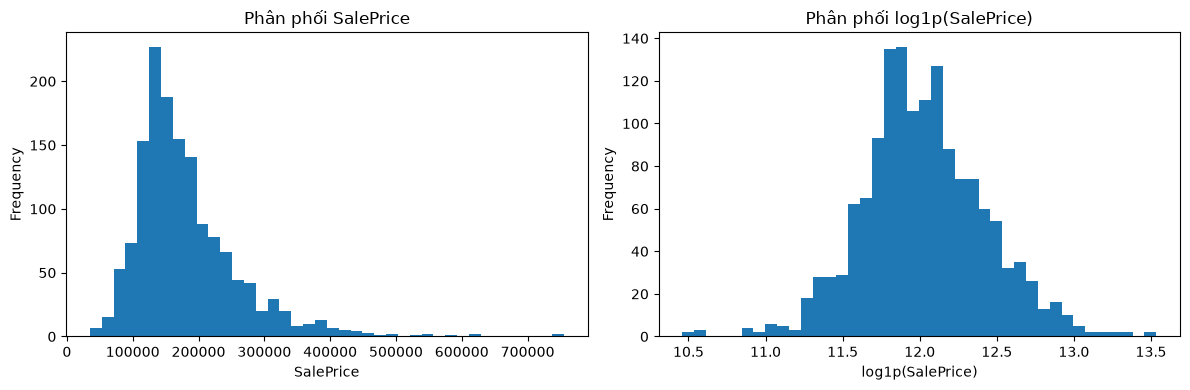

Skew SalePrice       : 1.8828757597682129
Skew log1p(SalePrice): 0.12134661989685329


In [7]:
# SalePrice trước và sau log1p
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train["SalePrice"], bins=40)
axes[0].set_title("Phân phối SalePrice")
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("Frequency")

log_saleprice = np.log1p(train["SalePrice"])
axes[1].hist(log_saleprice, bins=40)
axes[1].set_title("Phân phối log1p(SalePrice)")
axes[1].set_xlabel("log1p(SalePrice)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(FIG_DIR / "saleprice_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Skew SalePrice       :", train["SalePrice"].skew())
print("Skew log1p(SalePrice):", log_saleprice.skew())

**Nhận xét cần dùng trong báo cáo:** `SalePrice` lệch phải rõ rệt. `log1p()` làm phân phối cân đối hơn, giúp MLP học ổn định hơn và đồng thời phù hợp với metric log-RMSE.

In [8]:
# Tương quan số với SalePrice
numeric_corr = (
    train.select_dtypes(include=np.number)
    .corr(numeric_only=True)["SalePrice"]
    .drop("SalePrice")
    .sort_values(key=np.abs, ascending=False)
)

print("Top tương quan tuyệt đối với SalePrice:")
display(numeric_corr.head(15).to_frame("corr_with_SalePrice"))

Top tương quan tuyệt đối với SalePrice:


,corr_with_SalePrice
OverallQual,0.7910
GrLivArea,0.7086
GarageCars,0.6404
GarageArea,0.6234
TotalBsmtSF,0.6136
1stFlrSF,0.6059
FullBath,0.5607
TotRmsAbvGrd,0.5337
YearBuilt,0.5229
YearRemodAdd,0.5071


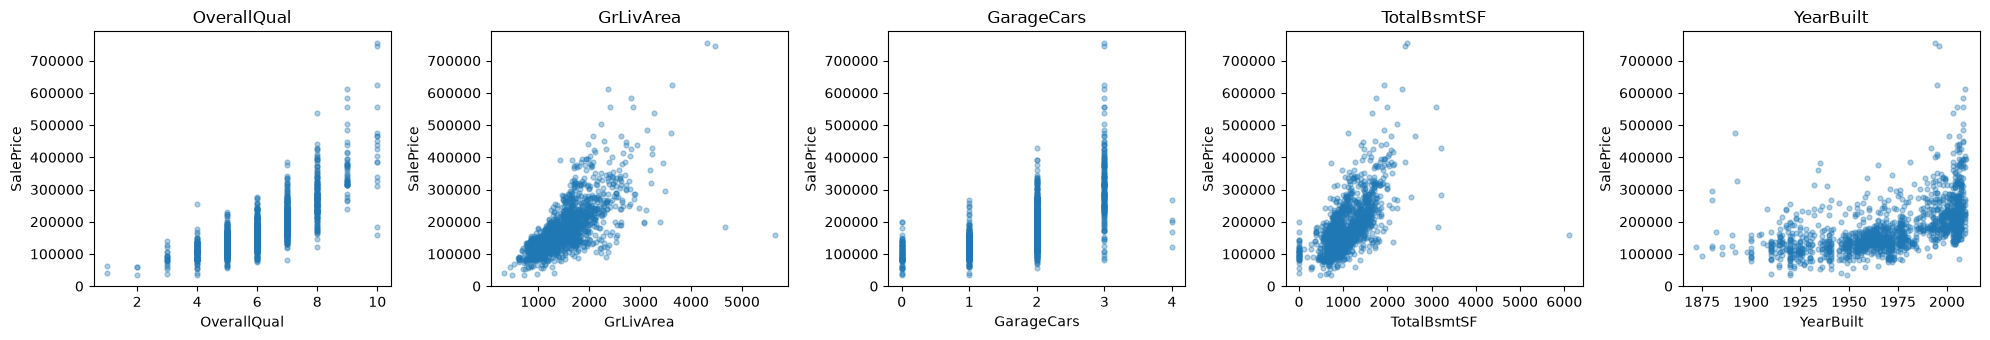

In [9]:
# Một số quan hệ tiêu biểu
selected_numeric = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt"]
selected_numeric = [c for c in selected_numeric if c in train.columns]

fig, axes = plt.subplots(1, len(selected_numeric), figsize=(4 * len(selected_numeric), 3.5))
if len(selected_numeric) == 1:
    axes = [axes]

for ax, col in zip(axes, selected_numeric):
    ax.scatter(train[col], train["SalePrice"], alpha=0.35, s=12)
    ax.set_xlabel(col)
    ax.set_ylabel("SalePrice")
    ax.set_title(col)

plt.tight_layout()
plt.savefig(FIG_DIR / "selected_numeric_vs_price.png", dpi=150, bbox_inches="tight")
plt.show()

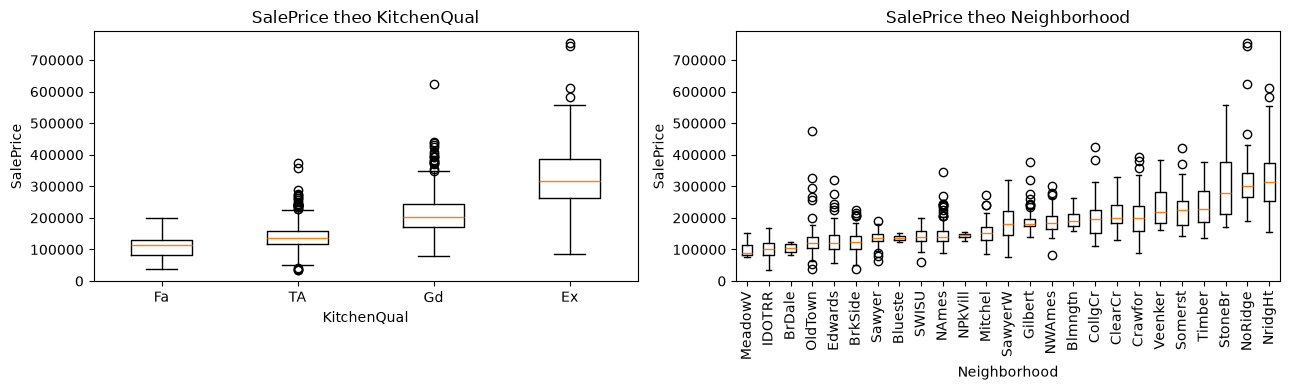

In [10]:
# Hai categorical quan trọng để quan sát
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

if "KitchenQual" in train.columns:
    kitchen_order = [x for x in ["Po", "Fa", "TA", "Gd", "Ex"] if x in train["KitchenQual"].dropna().unique()]
    kitchen_data = [train.loc[train["KitchenQual"] == k, "SalePrice"].values for k in kitchen_order]
    axes[0].boxplot(kitchen_data, tick_labels=kitchen_order)
    axes[0].set_title("SalePrice theo KitchenQual")
    axes[0].set_xlabel("KitchenQual")
    axes[0].set_ylabel("SalePrice")

if "Neighborhood" in train.columns:
    order = train.groupby("Neighborhood")["SalePrice"].median().sort_values().index.tolist()
    neigh_data = [train.loc[train["Neighborhood"] == k, "SalePrice"].values for k in order]
    axes[1].boxplot(neigh_data, tick_labels=order)
    axes[1].tick_params(axis="x", rotation=90)
    axes[1].set_title("SalePrice theo Neighborhood")
    axes[1].set_xlabel("Neighborhood")
    axes[1].set_ylabel("SalePrice")

plt.tight_layout()
plt.savefig(FIG_DIR / "categorical_vs_price.png", dpi=150, bbox_inches="tight")
plt.show()

# 5. Data Preparation — Leakage-safe Pipeline

## 5.1. Nguyên tắc

**Không** gộp train + test để tính median/mode/encoder.  
Quy trình đúng trong notebook này:

```text
train.csv
   ↓
X + y
   ↓
Train / Validation split
   ↓
FIT preprocessing trên Train fold
   ↓
Transform Train fold
Transform Validation fold
Transform Kaggle Test
```

Điều này giúp validation phản ánh đúng dữ liệu mà pipeline chưa từng nhìn thấy.

### Target scaling cho MLP
Sau `log1p`, target của MLP được chuẩn hóa bằng **mean/std chỉ từ training fold**. MLP học target chuẩn hóa để gradient ổn định hơn; khi đánh giá, prediction được đổi ngược về **log scale gốc** rồi mới tính RMSE/MAE/R². Ridge baseline vẫn học trực tiếp trên log target để giữ vai trò baseline đơn giản.

In [11]:
TARGET = "SalePrice"
ID_COL = "Id"

X_raw = train.drop(columns=[TARGET, ID_COL]).copy()
y_log = np.log1p(train[TARGET].values.astype(np.float64))
X_test_raw = test.drop(columns=[ID_COL]).copy()

X_train_raw, X_val_raw, y_train_log, y_val_log = train_test_split(
    X_raw,
    y_log,
    test_size=CONFIG["data"]["validation_size"],
    random_state=CONFIG["data"]["split_seed"],
)

# Target scaling: chỉ học mean/std từ training fold để không leakage.
Y_LOG_MEAN = float(np.mean(y_train_log))
Y_LOG_STD = float(np.std(y_train_log))
y_train_scaled = (y_train_log - Y_LOG_MEAN) / Y_LOG_STD
y_val_scaled = (y_val_log - Y_LOG_MEAN) / Y_LOG_STD

print("X_train_raw:", X_train_raw.shape)
print("X_val_raw  :", X_val_raw.shape)
print("X_test_raw :", X_test_raw.shape)
print("y_train_log:", y_train_log.shape)
print("y_val_log  :", y_val_log.shape)
print(f"Target log mean/std (fit on train fold): {Y_LOG_MEAN:.4f} / {Y_LOG_STD:.4f}")

X_train_raw: (1168, 79)
X_val_raw  : (292, 79)
X_test_raw : (1459, 79)
y_train_log: (1168,)
y_val_log  : (292,)
Target log mean/std (fit on train fold): 12.0307 / 0.3904


## 5.2. Quy tắc xử lý missing và encoding

### Missing categorical có nghĩa là “không có tiện ích”
Ví dụ `GarageType`, `BsmtQual`, `FireplaceQu`, `PoolQC`... sẽ điền bằng `"None"`.

### Missing numeric gắn với tiện ích không tồn tại
Ví dụ `GarageArea`, `GarageCars`, `TotalBsmtSF`... sẽ điền bằng `0`.

### `LotFrontage`
Dùng **median theo `Neighborhood`**, nhưng thống kê này chỉ được học từ training fold. Nếu gặp neighborhood mới thì dùng global median của training fold.

### Ordinal Encoding
Những biến có thứ tự tự nhiên được map sang số, ví dụ:
`Ex > Gd > TA > Fa > Po > None`.

### Nominal Encoding
Các biến danh nghĩa còn lại dùng `OneHotEncoder(handle_unknown="ignore")`.

### Scaling
Các biến numeric + ordinal dùng `StandardScaler`. One-hot giữ nguyên 0/1.

In [12]:
NONE_CAT_COLS = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature", "MasVnrType",
]

ZERO_NUM_COLS = [
    "GarageYrBlt", "GarageArea", "GarageCars",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "MasVnrArea",
]

QUAL_MAP = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}
QUAL_COLS = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
    "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC",
]

ORDINAL_MAPS = {
    **{col: QUAL_MAP for col in QUAL_COLS},
    "BsmtExposure": {"Gd": 4, "Av": 3, "Mn": 2, "No": 1, "None": 0},
    "BsmtFinType1": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0},
    "BsmtFinType2": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0},
    "GarageFinish": {"Fin": 3, "RFn": 2, "Unf": 1, "None": 0},
    "Fence": {"GdPrv": 4, "MnPrv": 3, "GdWo": 2, "MnWw": 1, "None": 0},
    "PavedDrive": {"Y": 2, "P": 1, "N": 0},
    "CentralAir": {"Y": 1, "N": 0},
}

In [13]:
class HousePreprocessor:
    """
    Leakage-safe preprocessor:
    - fit thống kê/encoder/scaler trên training data;
    - transform validation/test bằng các tham số đã học.
    """

    def __init__(self):
        self.cat_modes = {}
        self.num_medians = {}
        self.lotfrontage_by_neighborhood = None
        self.lotfrontage_global = None
        self.nominal_cols = []
        self.numeric_cols = []
        self.encoder = None
        self.scaler = None
        self.feature_names_ = None

    @staticmethod
    def _normalize_types(df):
        df = df.copy()
        # MSSubClass là mã loại nhà; xử lý như categorical thay vì một đại lượng liên tục.
        if "MSSubClass" in df.columns:
            df["MSSubClass"] = df["MSSubClass"].astype(str)
        return df

    def _apply_base_missing(self, df, fit=False):
        df = self._normalize_types(df)

        # 1) NaN có nghĩa là không có tiện ích
        for col in NONE_CAT_COLS:
            if col in df.columns:
                df[col] = df[col].fillna("None")

        # 2) Numeric liên quan tiện ích không tồn tại -> 0
        for col in ZERO_NUM_COLS:
            if col in df.columns:
                df[col] = df[col].fillna(0)

        # 3) LotFrontage theo Neighborhood
        if "LotFrontage" in df.columns and "Neighborhood" in df.columns:
            if fit:
                tmp = df[["Neighborhood", "LotFrontage"]].dropna(subset=["LotFrontage"])
                self.lotfrontage_by_neighborhood = tmp.groupby("Neighborhood")["LotFrontage"].median()
                self.lotfrontage_global = df["LotFrontage"].median()

            def fill_lotfrontage(row):
                if pd.notna(row["LotFrontage"]):
                    return row["LotFrontage"]
                if self.lotfrontage_by_neighborhood is not None:
                    value = self.lotfrontage_by_neighborhood.get(row["Neighborhood"], np.nan)
                    if pd.notna(value):
                        return value
                return self.lotfrontage_global

            df["LotFrontage"] = df.apply(fill_lotfrontage, axis=1)

        # 4) Các categorical còn thiếu -> mode học từ train
        cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
        if fit:
            for col in cat_cols:
                if df[col].isna().any():
                    mode = df[col].mode(dropna=True)
                    self.cat_modes[col] = mode.iloc[0] if len(mode) else "Missing"

        for col, mode in self.cat_modes.items():
            if col in df.columns:
                df[col] = df[col].fillna(mode)

        # 5) Các numeric còn thiếu -> median học từ train
        num_cols = df.select_dtypes(include=np.number).columns.tolist()
        if fit:
            for col in num_cols:
                if df[col].isna().any():
                    self.num_medians[col] = df[col].median()

        for col, median in self.num_medians.items():
            if col in df.columns:
                df[col] = df[col].fillna(median)

        return df

    @staticmethod
    def _apply_ordinal_encoding(df):
        df = df.copy()
        for col, mapping in ORDINAL_MAPS.items():
            if col in df.columns:
                # Giá trị không biết (nếu có) được xem là 0 để transform không lỗi.
                df[col] = df[col].map(mapping).fillna(0).astype(float)
        return df

    def fit(self, X):
        df = self._apply_base_missing(X, fit=True)
        df = self._apply_ordinal_encoding(df)

        self.nominal_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
        self.numeric_cols = [c for c in df.columns if c not in self.nominal_cols]

        # OneHotEncoder tương thích nhiều phiên bản sklearn
        try:
            self.encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        except TypeError:
            self.encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

        if self.nominal_cols:
            self.encoder.fit(df[self.nominal_cols])

        self.scaler = StandardScaler()
        self.scaler.fit(df[self.numeric_cols])

        ohe_names = []
        if self.nominal_cols:
            ohe_names = self.encoder.get_feature_names_out(self.nominal_cols).tolist()
        self.feature_names_ = self.numeric_cols + ohe_names
        return self

    def transform(self, X):
        df = self._apply_base_missing(X, fit=False)
        df = self._apply_ordinal_encoding(df)

        # Bảo đảm các numeric cột đã fit tồn tại và theo đúng thứ tự.
        num = self.scaler.transform(df[self.numeric_cols])

        if self.nominal_cols:
            cat = self.encoder.transform(df[self.nominal_cols])
            out = np.hstack([num, cat])
        else:
            out = num

        out = np.asarray(out, dtype=np.float32)
        return out

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [14]:
preprocessor = HousePreprocessor()
X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test_kaggle = preprocessor.transform(X_test_raw)

print("Sau preprocessing:")
print("X_train      :", X_train.shape)
print("X_val        :", X_val.shape)
print("X_test_kaggle:", X_test_kaggle.shape)
print("Số feature   :", len(preprocessor.feature_names_))

assert X_train.shape[1] == X_val.shape[1] == X_test_kaggle.shape[1]
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test_kaggle).all()

print("NaN/Inf check: PASS")
print("10 feature đầu:", preprocessor.feature_names_[:10])

Sau preprocessing:
X_train      : (1168, 248)
X_val        : (292, 248)
X_test_kaggle: (1459, 248)
Số feature   : 248
NaN/Inf check: PASS
10 feature đầu: ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'ExterQual', 'ExterCond', 'BsmtQual']


# 6. Baseline Model — Ridge Regression

Baseline không thay thế MLP. Nó tạo một **mốc tham chiếu** để biết mạng neural có thực sự cải thiện dự đoán hay không.

Ridge được train trên **cùng dữ liệu đã preprocessing** và đánh giá trên **cùng validation set**.

In [15]:
def regression_metrics(y_true_log, pred_log):
    y_true_log = np.asarray(y_true_log).ravel()
    pred_log = np.asarray(pred_log).ravel()

    rmse_log = np.sqrt(mean_squared_error(y_true_log, pred_log))

    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(pred_log)

    mae_usd = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "rmse_log": rmse_log,
        "mae_usd": mae_usd,
        "r2": r2,
    }


ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train_log)
ridge_pred_log = ridge.predict(X_val)
ridge_metrics = regression_metrics(y_val_log, ridge_pred_log)

print("RIDGE BASELINE")
print(f"RMSE (log): {ridge_metrics['rmse_log']:.4f}")
print(f"MAE  ($)  : ${ridge_metrics['mae_usd']:,.2f}")
print(f"R²        : {ridge_metrics['r2']:.4f}")

RIDGE BASELINE
RMSE (log): 0.1263
MAE  ($)  : $15,665.58
R²        : 0.9261


# 7. PyTorch Dataset & DataLoader

MLP nhận input dạng tensor `float32`.  
Validation không shuffle. Training shuffle nhưng generator được gắn seed để tái lập kết quả.

In [16]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val_scaled, dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test_kaggle, dtype=torch.float32)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=CONFIG["train"]["batch_size"],
    shuffle=False,
)

def make_train_loader(seed, batch_size=None):
    if batch_size is None:
        batch_size = CONFIG["train"]["batch_size"]
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
    )

print("X_train_t:", X_train_t.shape)
print("y_train_t (scaled target):", y_train_t.shape)
print("X_val_t  :", X_val_t.shape)

X_train_t: torch.Size([1168, 248])
y_train_t (scaled target): torch.Size([1168, 1])
X_val_t  : torch.Size([292, 248])


# 8. Define MLP

Mạng sử dụng:

- `Linear`
- `ReLU`
- `Dropout` nhẹ để regularization
- một output neuron cho **target log đã chuẩn hóa**; khi đánh giá sẽ inverse-transform về `log1p(SalePrice)`

Không dùng activation ở output vì đây là regression.

In [17]:
class HousePriceMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=(128, 64, 32), dropout=0.10):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for i, hidden_dim in enumerate(hidden_dims):
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            # Dropout ở các hidden layer; dùng nhẹ để tránh overfitting.
            if dropout > 0 and i < len(hidden_dims) - 1:
                layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


example_model = HousePriceMLP(
    input_dim=X_train.shape[1],
    hidden_dims=(128, 64, 32),
    dropout=CONFIG["train"]["dropout"],
)
print(example_model)

HousePriceMLP(
  (net): Sequential(
    (0): Linear(in_features=248, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)


# 9. Training — MSELoss + Adam + Early Stopping

Mỗi epoch thực hiện:

```text
model.train()
→ forward
→ MSELoss
→ backward
→ optimizer.step()

model.eval()
→ torch.no_grad()
→ validation loss
```

**Early Stopping:** nếu validation loss không cải thiện trong `patience` epoch, dừng và khôi phục trọng số tốt nhất.

In [18]:
def train_model(
    hidden_dims,
    seed=42,
    learning_rate=None,
    dropout=None,
    max_epochs=None,
    patience=None,
    verbose=True,
):
    learning_rate = learning_rate or CONFIG["train"]["learning_rate"]
    dropout = CONFIG["train"]["dropout"] if dropout is None else dropout
    max_epochs = max_epochs or CONFIG["train"]["max_epochs"]
    patience = patience or CONFIG["train"]["patience"]
    min_delta = CONFIG["train"]["min_delta"]

    set_seed(seed)
    train_loader = make_train_loader(seed)

    model = HousePriceMLP(
        input_dim=X_train.shape[1],
        hidden_dims=tuple(hidden_dims),
        dropout=dropout,
    ).to(DEVICE)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate,
        weight_decay=CONFIG["train"]["weight_decay"],
    )

    history = {
        "train_mse": [],
        "val_mse": [],
        "train_rmse": [],
        "val_rmse": [],
    }

    best_val = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        # ----- Train -----
        model.train()
        total_train_sse = 0.0
        total_train_n = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

            batch_n = len(xb)
            total_train_sse += loss.item() * batch_n
            total_train_n += batch_n

        train_mse = total_train_sse / total_train_n

        # ----- Validation -----
        model.eval()
        total_val_sse = 0.0
        total_val_n = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                pred = model(xb)
                loss = criterion(pred, yb)

                batch_n = len(xb)
                total_val_sse += loss.item() * batch_n
                total_val_n += batch_n

        val_mse = total_val_sse / total_val_n

        history["train_mse"].append(train_mse)
        history["val_mse"].append(val_mse)
        history["train_rmse"].append(np.sqrt(train_mse) * Y_LOG_STD)
        history["val_rmse"].append(np.sqrt(val_mse) * Y_LOG_STD)

        # ----- Early Stopping -----
        if val_mse < best_val - min_delta:
            best_val = val_mse
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose and (epoch == 1 or epoch % 20 == 0):
            print(
                f"Epoch {epoch:3d}/{max_epochs} | "
                f"Train RMSE(log): {np.sqrt(train_mse) * Y_LOG_STD:.4f} | "
                f"Val RMSE(log): {np.sqrt(val_mse) * Y_LOG_STD:.4f}"
            )

        if epochs_without_improvement >= patience:
            if verbose:
                print(f"Early stopping tại epoch {epoch}. Best epoch = {best_epoch}")
            break

    model.load_state_dict(best_state)

    # Prediction validation bằng best weights
    model.eval()
    with torch.no_grad():
        pred_scaled = model(X_val_t.to(DEVICE)).cpu().numpy().ravel()
        pred_log = pred_scaled * Y_LOG_STD + Y_LOG_MEAN

    metrics = regression_metrics(y_val_log, pred_log)
    metrics["best_epoch"] = best_epoch
    metrics["best_val_mse"] = best_val

    return model, history, metrics, pred_log

In [19]:
# Chạy một MLP baseline trước khi tuning kiến trúc
BASELINE_ARCH = [128, 64, 32]
BASELINE_SEED = 42

baseline_mlp, baseline_history, baseline_mlp_metrics, baseline_mlp_pred_log = train_model(
    hidden_dims=BASELINE_ARCH,
    seed=BASELINE_SEED,
    verbose=True,
)

print("\nMLP BASELINE")
print("Architecture:", BASELINE_ARCH)
print("Best epoch  :", baseline_mlp_metrics["best_epoch"])
print(f"RMSE (log)  : {baseline_mlp_metrics['rmse_log']:.4f}")
print(f"MAE  ($)    : ${baseline_mlp_metrics['mae_usd']:,.2f}")
print(f"R²          : {baseline_mlp_metrics['r2']:.4f}")

Epoch   1/120 | Train RMSE(log): 0.3618 | Val RMSE(log): 0.3340
Epoch  20/120 | Train RMSE(log): 0.0976 | Val RMSE(log): 0.1361
Early stopping tại epoch 37. Best epoch = 25

MLP BASELINE
Architecture: [128, 64, 32]
Best epoch  : 25
RMSE (log)  : 0.1330
MAE  ($)    : $15,977.49
R²          : 0.8823


# 10. Evaluation

Đánh giá gồm:

1. RMSE trên log scale — metric chính.
2. MAE theo USD.
3. R² trên giá thực tế.
4. Train/Validation RMSE theo epoch.
5. Actual vs Predicted.
6. Phân phối residual.

In [20]:
# So sánh Ridge và MLP baseline
comparison = pd.DataFrame([
    {
        "model": "Ridge",
        "rmse_log": ridge_metrics["rmse_log"],
        "mae_usd": ridge_metrics["mae_usd"],
        "r2": ridge_metrics["r2"],
    },
    {
        "model": f"MLP {BASELINE_ARCH}",
        "rmse_log": baseline_mlp_metrics["rmse_log"],
        "mae_usd": baseline_mlp_metrics["mae_usd"],
        "r2": baseline_mlp_metrics["r2"],
    },
])

display(comparison)

,model,rmse_log,mae_usd,r2
0,Ridge,0.1263,"15,665.5788",0.9261
1,"MLP [128, 64, 32]",0.1330,"15,977.4926",0.8823


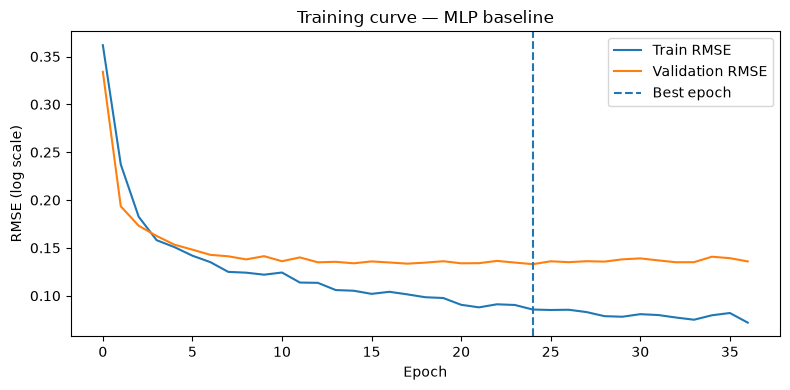

In [21]:
# Loss curve
plt.figure(figsize=(8, 4))
plt.plot(baseline_history["train_rmse"], label="Train RMSE")
plt.plot(baseline_history["val_rmse"], label="Validation RMSE")
plt.axvline(baseline_mlp_metrics["best_epoch"] - 1, linestyle="--", label="Best epoch")
plt.xlabel("Epoch")
plt.ylabel("RMSE (log scale)")
plt.title("Training curve — MLP baseline")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_training_curve.png", dpi=150, bbox_inches="tight")
plt.show()

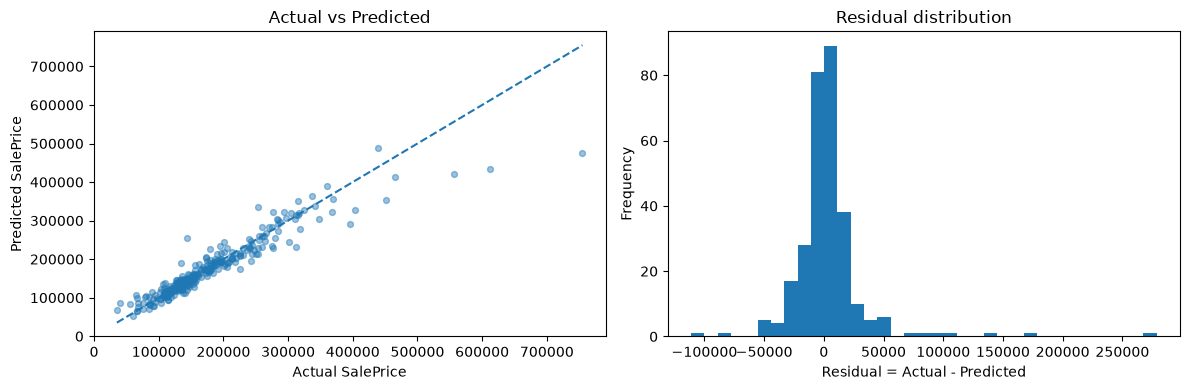

In [22]:
# Actual vs Predicted + residual
true_price = np.expm1(y_val_log)
pred_price = np.expm1(baseline_mlp_pred_log)
residual = true_price - pred_price

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(true_price, pred_price, alpha=0.45, s=18)
low = min(true_price.min(), pred_price.min())
high = max(true_price.max(), pred_price.max())
axes[0].plot([low, high], [low, high], linestyle="--")
axes[0].set_xlabel("Actual SalePrice")
axes[0].set_ylabel("Predicted SalePrice")
axes[0].set_title("Actual vs Predicted")

axes[1].hist(residual, bins=35)
axes[1].set_xlabel("Residual = Actual - Predicted")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Residual distribution")

plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_prediction_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

# 11. Architecture Experiments

Ba kiến trúc được lấy theo hướng source House Prices tham khảo:

- `64 → 32 → 16`
- `128 → 64 → 32`
- `256 → 128 → 64`

Ở bước này, mọi kiến trúc dùng **cùng một seed = 42** để so sánh sơ bộ công bằng.  
Khác source cũ, notebook sử dụng **best validation checkpoint + Early Stopping**, không lấy model ở epoch cuối một cách máy móc.

In [23]:
architecture_results = []
architecture_models = {}
architecture_histories = {}

for arch in CONFIG["experiments"]["architectures"]:
    label = "-".join(map(str, arch))
    print("\n" + "=" * 70)
    print("Architecture:", label)

    # Reuse baseline MLP nếu trùng đúng architecture + seed để tránh train lại.
    if list(arch) == list(BASELINE_ARCH):
        model = baseline_mlp
        history = baseline_history
        metrics = baseline_mlp_metrics
    else:
        model, history, metrics, _ = train_model(
            hidden_dims=arch,
            seed=42,
            verbose=False,
        )

    architecture_models[label] = model
    architecture_histories[label] = history
    architecture_results.append({
        "architecture": label,
        "seed": 42,
        "best_epoch": metrics["best_epoch"],
        "rmse_log": metrics["rmse_log"],
        "mae_usd": metrics["mae_usd"],
        "r2": metrics["r2"],
    })

    print(
        f"Best epoch={metrics['best_epoch']} | "
        f"RMSE={metrics['rmse_log']:.4f} | "
        f"MAE=${metrics['mae_usd']:,.2f} | "
        f"R²={metrics['r2']:.4f}"
    )

architecture_df = pd.DataFrame(architecture_results).sort_values("rmse_log").reset_index(drop=True)
display(architecture_df)

selected_arch_label = architecture_df.iloc[0]["architecture"]
selected_arch = [int(x) for x in selected_arch_label.split("-")]
print("Architecture được chọn để kiểm tra stability:", selected_arch)


Architecture: 64-32-16
Best epoch=24 | RMSE=0.1321 | MAE=$15,722.19 | R²=0.8983

Architecture: 128-64-32
Best epoch=25 | RMSE=0.1330 | MAE=$15,977.49 | R²=0.8823

Architecture: 256-128-64
Best epoch=13 | RMSE=0.1288 | MAE=$15,249.02 | R²=0.8951


,architecture,seed,best_epoch,rmse_log,mae_usd,r2
0,256-128-64,42,13,0.1288,"15,249.0196",0.8951
1,64-32-16,42,24,0.1321,"15,722.1947",0.8983
2,128-64-32,42,25,0.1330,"15,977.4926",0.8823


Architecture được chọn để kiểm tra stability: [256, 128, 64]


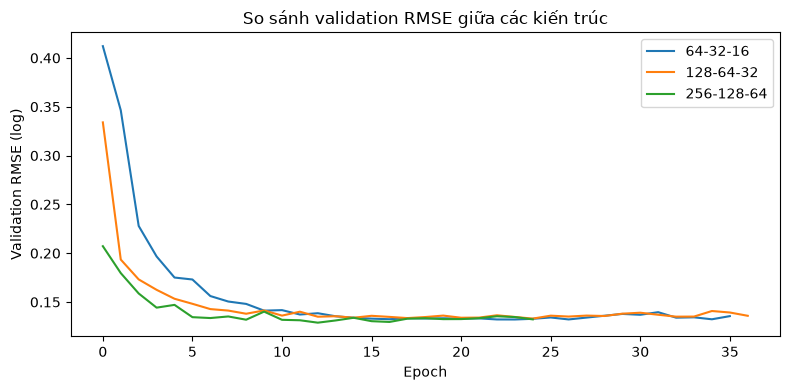

In [24]:
plt.figure(figsize=(8, 4))
for label, history in architecture_histories.items():
    plt.plot(history["val_rmse"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation RMSE (log)")
plt.title("So sánh validation RMSE giữa các kiến trúc")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "architecture_val_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

# 12. Stability Test — Nhiều Seed

Sau bước Architecture Experiments, ta lấy **architecture tốt nhất trên validation set cố định (seed 42)** làm ứng viên.

Sau đó cùng architecture đó được chạy lại với các seed:

```python
[42, 123, 2026]
```

Mục tiêu của bước này không phải đổi validation set mà là đo ảnh hưởng của:

- random weight initialization;
- DataLoader shuffle.

Ta báo cáo **Mean RMSE ± Std RMSE** và median của best epoch. Đây là cách gom ý tưởng V1/V2/V3 vào một thí nghiệm có kiểm soát.

In [25]:
stability_results = []

# Kết quả seed=42 đã có từ Architecture Experiments -> reuse.
seed42_row = architecture_df.loc[architecture_df["architecture"] == selected_arch_label].iloc[0]
stability_results.append({
    "architecture": selected_arch_label,
    "seed": 42,
    "best_epoch": int(seed42_row["best_epoch"]),
    "rmse_log": float(seed42_row["rmse_log"]),
    "mae_usd": float(seed42_row["mae_usd"]),
    "r2": float(seed42_row["r2"]),
})

for seed in CONFIG["experiments"]["model_seeds"]:
    if seed == 42:
        continue

    print(f"Training architecture={selected_arch_label}, seed={seed} ...")
    _, _, metrics, _ = train_model(
        hidden_dims=selected_arch,
        seed=seed,
        verbose=False,
    )

    stability_results.append({
        "architecture": selected_arch_label,
        "seed": seed,
        "best_epoch": metrics["best_epoch"],
        "rmse_log": metrics["rmse_log"],
        "mae_usd": metrics["mae_usd"],
        "r2": metrics["r2"],
    })

stability_df = pd.DataFrame(stability_results).sort_values("seed").reset_index(drop=True)
display(stability_df)

stability_df.to_csv(OUTPUT_DIR / "experiment_results.csv", index=False)
print("Đã lưu:", OUTPUT_DIR / "experiment_results.csv")

Training architecture=256-128-64, seed=123 ...
Training architecture=256-128-64, seed=2026 ...


,architecture,seed,best_epoch,rmse_log,mae_usd,r2
0,256-128-64,42,13,0.1288,"15,249.0196",0.8951
1,256-128-64,123,17,0.1308,"15,935.0341",0.9065
2,256-128-64,2026,8,0.1326,"15,943.7936",0.8965


Đã lưu: outputs/experiment_results.csv


In [26]:
stability_summary = pd.DataFrame([{
    "architecture": selected_arch_label,
    "mean_rmse": stability_df["rmse_log"].mean(),
    "std_rmse": stability_df["rmse_log"].std(ddof=1),
    "mean_mae": stability_df["mae_usd"].mean(),
    "mean_r2": stability_df["r2"].mean(),
    "median_best_epoch": stability_df["best_epoch"].median(),
}])

display(stability_summary)

best_arch_label = selected_arch_label
best_arch = selected_arch
final_epochs = max(1, int(round(stability_df["best_epoch"].median())))

print("Best architecture:", best_arch)
print("Mean RMSE(log):", f"{stability_summary.iloc[0]['mean_rmse']:.4f}")
print("Std  RMSE(log):", f"{stability_summary.iloc[0]['std_rmse']:.4f}")
print("Final training epochs (median best epoch):", final_epochs)

,architecture,mean_rmse,std_rmse,mean_mae,mean_r2,median_best_epoch
0,256-128-64,0.1307,0.0019,"15,709.2824",0.8994,13.0000


Best architecture: [256, 128, 64]
Mean RMSE(log): 0.1307
Std  RMSE(log): 0.0019
Final training epochs (median best epoch): 13


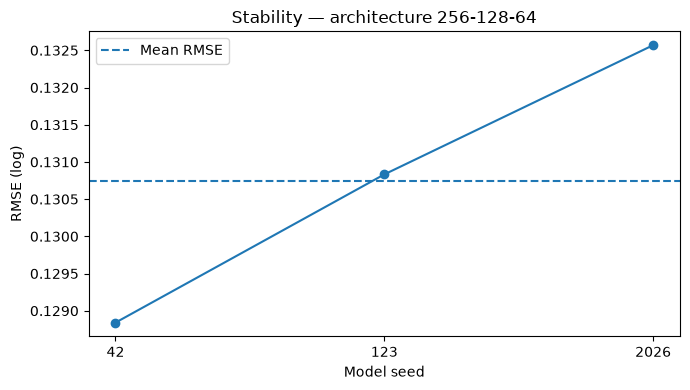

In [27]:
# Thể hiện độ dao động RMSE giữa các seed của architecture đã chọn
plt.figure(figsize=(7, 4))
plt.plot(stability_df["seed"].astype(str), stability_df["rmse_log"], marker="o")
plt.axhline(stability_df["rmse_log"].mean(), linestyle="--", label="Mean RMSE")
plt.xlabel("Model seed")
plt.ylabel("RMSE (log)")
plt.title(f"Stability — architecture {selected_arch_label}")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stability_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

# 13. Final Model — Refit trên toàn bộ train.csv

Sau khi **chọn architecture và số epoch** bằng validation experiments:

1. Fit lại preprocessor trên **toàn bộ training data**.
2. Transform toàn bộ training data và Kaggle test.
3. Train final MLP trong số epoch đã chọn.
4. Không dùng validation để lựa chọn thêm hyperparameter ở bước này.

Điều này giúp tận dụng toàn bộ 1,460 mẫu train cho final model.

In [28]:
# Fit preprocessing trên toàn bộ train sau khi đã chốt architecture/hyperparameters
final_preprocessor = HousePreprocessor()
X_full = final_preprocessor.fit_transform(X_raw)
X_kaggle_final = final_preprocessor.transform(X_test_raw)
y_full_log = y_log.copy()

# Target scaler cuối cùng được fit trên toàn bộ train.
Y_FULL_MEAN = float(np.mean(y_full_log))
Y_FULL_STD = float(np.std(y_full_log))
y_full_scaled = (y_full_log - Y_FULL_MEAN) / Y_FULL_STD

X_full_t = torch.tensor(X_full, dtype=torch.float32)
y_full_t = torch.tensor(y_full_scaled, dtype=torch.float32).view(-1, 1)
X_kaggle_final_t = torch.tensor(X_kaggle_final, dtype=torch.float32)

print("X_full:", X_full.shape)
print("X_kaggle_final:", X_kaggle_final.shape)
print(f"Final target log mean/std: {Y_FULL_MEAN:.4f} / {Y_FULL_STD:.4f}")
assert X_full.shape[1] == X_kaggle_final.shape[1]

X_full: (1460, 250)
X_kaggle_final: (1459, 250)
Final target log mean/std: 12.0241 / 0.3993


In [29]:
def train_final_model(hidden_dims, epochs, seed=42):
    set_seed(seed)

    generator = torch.Generator()
    generator.manual_seed(seed)

    loader = DataLoader(
        TensorDataset(X_full_t, y_full_t),
        batch_size=CONFIG["train"]["batch_size"],
        shuffle=True,
        generator=generator,
    )

    model = HousePriceMLP(
        input_dim=X_full.shape[1],
        hidden_dims=tuple(hidden_dims),
        dropout=CONFIG["train"]["dropout"],
    ).to(DEVICE)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=CONFIG["train"]["learning_rate"],
        weight_decay=CONFIG["train"]["weight_decay"],
    )

    losses = []

    for epoch in range(1, epochs + 1):
        model.train()
        total_sse = 0.0
        total_n = 0

        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

            total_sse += loss.item() * len(xb)
            total_n += len(xb)

        mse = total_sse / total_n
        losses.append(mse)

        if epoch == 1 or epoch % 25 == 0 or epoch == epochs:
            print(f"Final epoch {epoch:3d}/{epochs} | Train RMSE(log): {np.sqrt(mse) * Y_FULL_STD:.4f}")

    return model, losses


FINAL_SEED = 42
final_model, final_losses = train_final_model(
    hidden_dims=best_arch,
    epochs=final_epochs,
    seed=FINAL_SEED,
)

Final epoch   1/13 | Train RMSE(log): 0.3190
Final epoch  13/13 | Train RMSE(log): 0.0884


In [30]:
# Lưu final model và metadata
model_artifact = {
    "state_dict": final_model.state_dict(),
    "input_dim": X_full.shape[1],
    "hidden_dims": best_arch,
    "dropout": CONFIG["train"]["dropout"],
    "epochs": final_epochs,
    "seed": FINAL_SEED,
    "target_log_mean": Y_FULL_MEAN,
    "target_log_std": Y_FULL_STD,
    "feature_names": final_preprocessor.feature_names_,
}

torch.save(model_artifact, OUTPUT_DIR / "best_model.pt")
print("Đã lưu:", OUTPUT_DIR / "best_model.pt")

Đã lưu: outputs/best_model.pt


# 14. Kaggle Prediction + Sanity Check

Dự đoán của MLP đang ở log scale. Ta đảo về USD bằng:

```python
np.expm1(pred_log)
```

Trước khi xuất file nộp, notebook kiểm tra:

- min / max / median / quantiles;
- giá <= 0;
- prediction cực lớn so với miền `SalePrice` trong train.

**Không tự động clip prediction chỉ để kết quả nhìn đẹp.** Nếu có extreme prediction, cần xem lại model/preprocessing trước.

In [31]:
final_model.eval()
with torch.no_grad():
    kaggle_pred_scaled = final_model(X_kaggle_final_t.to(DEVICE)).cpu().numpy().ravel()

kaggle_pred_log = kaggle_pred_scaled * Y_FULL_STD + Y_FULL_MEAN
kaggle_pred_price = np.expm1(kaggle_pred_log)

pred_summary = pd.Series(kaggle_pred_price, name="PredictedSalePrice").describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
)
train_summary = train["SalePrice"].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
)

print("PREDICTION SUMMARY")
display(pred_summary.to_frame().T)

print("TRAIN SALEPRICE SUMMARY")
display(train_summary.to_frame().T)

n_non_positive = int((kaggle_pred_price <= 0).sum())
train_max = train["SalePrice"].max()
max_pred = kaggle_pred_price.max()

print("Non-positive predictions:", n_non_positive)
print(f"Train max SalePrice : ${train_max:,.2f}")
print(f"Prediction max      : ${max_pred:,.2f}")

if n_non_positive > 0:
    print("WARNING: Có prediction <= 0. Cần kiểm tra mô hình trước khi nộp.")

if max_pred > train_max * 3:
    print("WARNING: Có prediction cực lớn (> 3 lần max của train). Cần kiểm tra outlier/model stability.")
else:
    print("Sanity check mức giá cực đại: không phát hiện cảnh báo theo ngưỡng đang dùng.")

PREDICTION SUMMARY


,count,mean,std,min,1%,5%,50%,95%,99%,max
PredictedSalePrice,"1,459.0000","177,152.0469","75,921.1562","44,620.7852","61,729.9204","88,853.0008","154,423.1406","343,670.6969","430,124.8619","576,635.2500"


TRAIN SALEPRICE SUMMARY


,count,mean,std,min,1%,5%,50%,95%,99%,max
SalePrice,"1,460.0000","180,921.1959","79,442.5029","34,900.0000","61,815.9700","88,000.0000","163,000.0000","326,100.0000","442,567.0100","755,000.0000"


Non-positive predictions: 0
Train max SalePrice : $755,000.00
Prediction max      : $576,635.25
Sanity check mức giá cực đại: không phát hiện cảnh báo theo ngưỡng đang dùng.


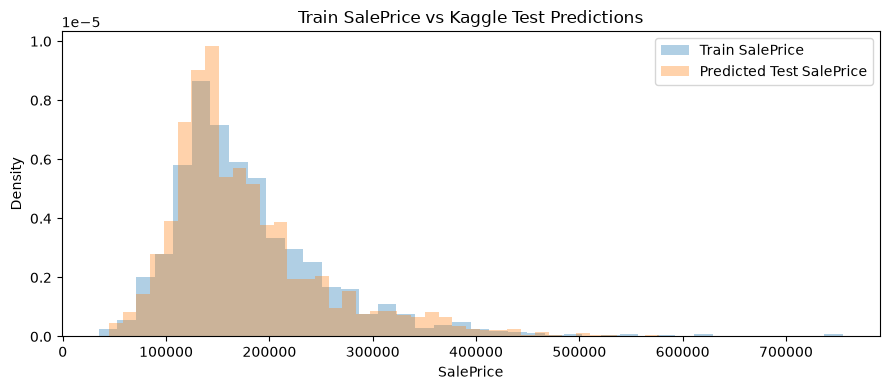

In [32]:
plt.figure(figsize=(9, 4))
plt.hist(train["SalePrice"], bins=40, density=True, alpha=0.35, label="Train SalePrice")
plt.hist(kaggle_pred_price, bins=40, density=True, alpha=0.35, label="Predicted Test SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Density")
plt.title("Train SalePrice vs Kaggle Test Predictions")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "train_vs_test_prediction_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# 15. Submission

File Kaggle phải có đúng 2 cột:

```text
Id,SalePrice
```

Sau khi ghi CSV, notebook đọc lại và kiểm tra:

- shape `(1459, 2)`;
- không có NaN;
- `Id` giữ đúng thứ tự của `test.csv`;
- `SalePrice > 0`.

In [33]:
submission = pd.DataFrame({
    "Id": test["Id"].values,
    "SalePrice": kaggle_pred_price,
})

submission_path = OUTPUT_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)

# Đọc lại để kiểm tra file thật đã ghi
submission_check = pd.read_csv(submission_path)

print("Submission path:", submission_path)
print("Submission shape:", submission_check.shape)
print("Columns:", submission_check.columns.tolist())
print("NaN count:", submission_check.isna().sum().sum())
print("Id preserved:", np.array_equal(submission_check["Id"].values, test["Id"].values))
print("All SalePrice > 0:", bool((submission_check["SalePrice"] > 0).all()))

display(submission_check.head(10))

Submission path: outputs/submission.csv
Submission shape: (1459, 2)
Columns: ['Id', 'SalePrice']
NaN count: 0
Id preserved: True
All SalePrice > 0: True


,Id,SalePrice
0,1461,"120,705.1900"
1,1462,"148,047.3900"
2,1463,"178,043.9400"
3,1464,"188,631.2000"
4,1465,"181,530.3000"
5,1466,"171,130.4200"
6,1467,"171,351.0600"
7,1468,"168,598.6200"
8,1469,"177,129.5600"
9,1470,"126,712.3100"


# 16. Conclusion / CRISP-DM Summary

Notebook hoàn tất toàn bộ vòng đời CRISP-DM:

| CRISP-DM | Nội dung đã thực hiện |
|---|---|
| **Business Understanding** | Xác định bài toán regression dự đoán `SalePrice` và metric log-RMSE |
| **Data Understanding** | Kiểm tra shape, dtype, missing values, target distribution, correlation và một số feature quan trọng |
| **Data Preparation** | Split trước preprocessing; imputation theo ngữ nghĩa; ordinal encoding; OHE; scaling; `log1p(SalePrice)` |
| **Modeling** | Ridge baseline + MLP PyTorch |
| **Evaluation** | RMSE log, MAE, R², learning curve, diagnostics, architecture comparison, stability across seeds |
| **Deployment** | Refit final model trên toàn bộ train, predict `test.csv`, sanity check, xuất `submission.csv` |

## Nội dung cần lấy vào báo cáo

1. **Bài toán:** Regression dự đoán giá nhà.
2. **Lý do log-transform:** giảm skew và phù hợp metric.
3. **Leakage control:** mọi statistics preprocessing trong validation experiment chỉ fit trên training fold.
4. **Baseline:** Ridge dùng làm mốc tham chiếu.
5. **MLP:** so sánh ba architecture.
6. **Stability:** báo cáo mean ± std RMSE qua nhiều seed, không chọn một lần chạy đẹp nhất.
7. **Final model:** chọn kiến trúc bằng validation, sau đó refit trên toàn bộ train.
8. **Deployment:** kiểm tra prediction trước khi tạo Kaggle submission.

In [34]:
# Tóm tắt tự động kết quả thí nghiệm để dùng trong báo cáo
best_row = stability_summary.iloc[0]
mlp_minus_ridge = best_row["mean_rmse"] - ridge_metrics["rmse_log"]

print("=" * 72)
print("LAB02 SUMMARY")
print("=" * 72)
print(f"Ridge RMSE(log): {ridge_metrics['rmse_log']:.4f}")
print(f"Best MLP architecture: {best_arch_label}")
print(f"Mean RMSE(log): {best_row['mean_rmse']:.4f}")
print(f"Std  RMSE(log): {best_row['std_rmse']:.4f}")
print(f"Mean MAE ($): ${best_row['mean_mae']:,.2f}")
print(f"Mean R²: {best_row['mean_r2']:.4f}")
print(f"Final epochs: {final_epochs}")
print(f"Submission: {submission_path}")

if mlp_minus_ridge < 0:
    print(f"MLP có RMSE thấp hơn Ridge khoảng {abs(mlp_minus_ridge):.4f} trên validation.")
else:
    print(f"Ridge có RMSE thấp hơn MLP trung bình khoảng {mlp_minus_ridge:.4f}; đây là kết quả cần nêu trung thực trong báo cáo.")
print("=" * 72)

LAB02 SUMMARY
Ridge RMSE(log): 0.1263
Best MLP architecture: 256-128-64
Mean RMSE(log): 0.1307
Std  RMSE(log): 0.0019
Mean MAE ($): $15,709.28
Mean R²: 0.8994
Final epochs: 13
Submission: outputs/submission.csv
Ridge có RMSE thấp hơn MLP trung bình khoảng 0.0044; đây là kết quả cần nêu trung thực trong báo cáo.
